In [9]:
# Notebook 9 — Cell 1: Load Selected Model and Dataset

import pandas as pd
import numpy as np
import joblib

from pathlib import Path

models_dir = Path("../models")
data_dir = Path("../data/processed")
reports_dir = Path("../reports")

reports_dir.mkdir(parents=True, exist_ok=True)

# Load trusted model artifacts received from Del
model = joblib.load(
    models_dir / "selected_churn_model.joblib"
)

config = joblib.load(
    models_dir / "selected_model_config.joblib"
)

# Load original training features for profiling
X_train = pd.read_csv(
    data_dir / "X_train_raw.csv"
)

y_train = pd.read_csv(
    data_dir / "y_train.csv"
).squeeze("columns")

print("=== SECONDARY LENS SETUP ===")

print("Selected model:", config["selected_model"])
print("Classification threshold:", config["selected_threshold"])

print("\nTraining features:", X_train.shape)
print("Training labels:", y_train.shape)

print("\nModel pipeline:", type(model).__name__)

assert config["selected_model"] == "Logistic Regression"
assert float(config["selected_threshold"]) == 0.60
assert X_train.shape == (5634, 19)
assert len(y_train) == 5634

print("\nNotebook 9 setup completed successfully!")

=== SECONDARY LENS SETUP ===
Selected model: Logistic Regression
Classification threshold: 0.6

Training features: (5634, 19)
Training labels: (5634,)

Model pipeline: Pipeline

Notebook 9 setup completed successfully!


In [10]:
# =========================================================
# Notebook 9 — Cell 2: Generate Customer Risk Scores
# =========================================================

import pandas as pd
import numpy as np

# Generate risk scores using the saved model
risk_scores = model.predict_proba(X_train)[:, 1]

# Apply final selected threshold
selected_threshold = float(config["selected_threshold"])

risk_predictions = (
    risk_scores >= selected_threshold
).astype(int)

# Create customer-level profiling dataset
customer_profiles = X_train.copy()

customer_profiles["Actual_Churn"] = y_train.to_numpy()
customer_profiles["Churn_Risk_Score"] = risk_scores
customer_profiles["Predicted_Churn"] = risk_predictions

# Check results
print("=== CUSTOMER RISK SCORING ===")

print("Total customers:", len(customer_profiles))
print("Selected threshold:", selected_threshold)

print("\nRisk score summary:")
print(customer_profiles["Churn_Risk_Score"].describe().round(4))

print("\nPredicted churn distribution:")
print(customer_profiles["Predicted_Churn"].value_counts())

print("\nFirst five customer profiles:")
display(
    customer_profiles[
        [
            "tenure",
            "Contract",
            "InternetService",
            "MonthlyCharges",
            "Churn_Risk_Score",
            "Predicted_Churn"
        ]
    ].head().round(4)
)

# Verify output
assert len(customer_profiles) == 5634
assert customer_profiles["Churn_Risk_Score"].between(0, 1).all()
assert customer_profiles["Churn_Risk_Score"].notna().all()

# Save profiling dataset
customer_profiles.to_csv(
    reports_dir / "customer_risk_profiles.csv",
    index=False
)

print("\nSaved: reports/customer_risk_profiles.csv")
print("Customer risk scoring completed successfully!")

=== CUSTOMER RISK SCORING ===
Total customers: 5634
Selected threshold: 0.6

Risk score summary:
count    5634.0000
mean        0.4138
std         0.2999
min         0.0055
25%         0.1148
50%         0.3897
75%         0.7009
max         0.9387
Name: Churn_Risk_Score, dtype: float64

Predicted churn distribution:
Predicted_Churn
0    3772
1    1862
Name: count, dtype: int64

First five customer profiles:


,tenure,Contract,InternetService,MonthlyCharges,Churn_Risk_Score,Predicted_Churn
0,35,Month-to-month,DSL,49.20,0.6104,1
1,15,Month-to-month,Fiber optic,75.10,0.5249,0
2,13,Two year,DSL,40.55,0.1060,0
3,26,Two year,DSL,73.50,0.2192,0
4,1,Month-to-month,DSL,44.55,0.6311,1



Saved: reports/customer_risk_profiles.csv
Customer risk scoring completed successfully!


=== CUSTOMER RISK SEGMENTATION ===
Risk_Segment  Customer_Count  Average_Risk_Score  Median_Risk_Score  Average_Tenure  Average_Monthly_Charges  Customer_Percentage
         Low            2375               0.110              0.087          49.097                   55.623               42.155
      Medium            1397               0.449              0.447          27.583                   63.048               24.796
        High            1862               0.775              0.786          14.974                   78.213               33.049


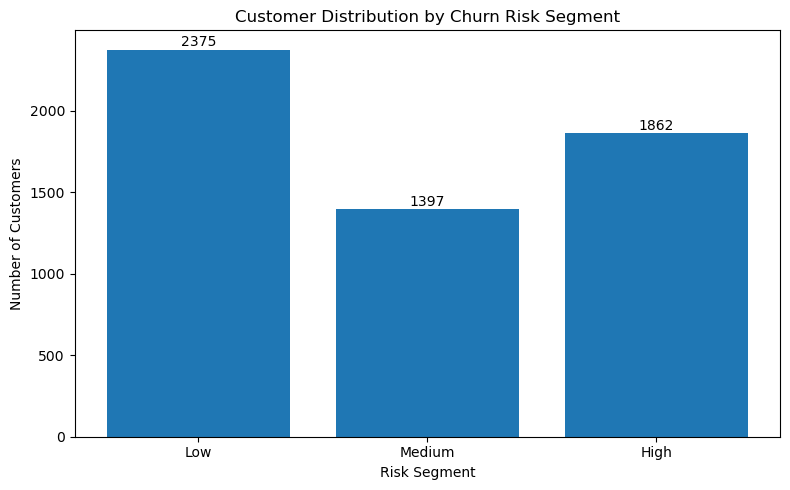


Saved: risk_segment_summary.csv
Saved: risk_segment_distribution.png
Updated: customer_risk_profiles.csv

Risk segmentation completed successfully!


In [11]:
# =========================================================
# Notebook 9 — Cell 3: Customer Risk Segmentation
# =========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Define risk categories
customer_profiles["Risk_Segment"] = pd.cut(
    customer_profiles["Churn_Risk_Score"],
    bins=[-np.inf, 0.30, 0.60, np.inf],
    labels=["Low", "Medium", "High"],
    right=False
)

# 2. Summarize customer segments
risk_summary = (
    customer_profiles
    .groupby("Risk_Segment", observed=True)
    .agg(
        Customer_Count=("Churn_Risk_Score", "size"),
        Average_Risk_Score=("Churn_Risk_Score", "mean"),
        Median_Risk_Score=("Churn_Risk_Score", "median"),
        Average_Tenure=("tenure", "mean"),
        Average_Monthly_Charges=("MonthlyCharges", "mean")
    )
    .reset_index()
)

risk_summary["Customer_Percentage"] = (
    risk_summary["Customer_Count"]
    / len(customer_profiles) * 100
)

# 3. Display results
print("=== CUSTOMER RISK SEGMENTATION ===")

print(risk_summary.round(3).to_string(index=False))

# 4. Visualize customer distribution
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    risk_summary["Risk_Segment"].astype(str),
    risk_summary["Customer_Count"]
)

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 20,
        str(int(bar.get_height())),
        ha="center"
    )

ax.set_title("Customer Distribution by Churn Risk Segment")
ax.set_xlabel("Risk Segment")
ax.set_ylabel("Number of Customers")

plt.tight_layout()

plt.savefig(
    reports_dir / "risk_segment_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 5. Validate results
assert risk_summary["Customer_Count"].sum() == len(customer_profiles)
assert customer_profiles["Risk_Segment"].notna().all()

# 6. Save outputs
risk_summary.to_csv(
    reports_dir / "risk_segment_summary.csv",
    index=False
)

customer_profiles.to_csv(
    reports_dir / "customer_risk_profiles.csv",
    index=False
)

print("\nSaved: risk_segment_summary.csv")
print("Saved: risk_segment_distribution.png")
print("Updated: customer_risk_profiles.csv")
print("\nRisk segmentation completed successfully!")

In [12]:
# =========================================================
# Notebook 9 — Cell 4: Profile Key Customer Characteristics
# =========================================================

import pandas as pd

profile_features = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "OnlineSecurity",
    "TechSupport",
    "PaperlessBilling"
]

print("=== CUSTOMER PROFILE ANALYSIS BY RISK SEGMENT ===")

segment_profile_tables = {}

for feature in profile_features:
    print(f"\n--- {feature} ---")
    
    profile_table = pd.crosstab(
        customer_profiles["Risk_Segment"],
        customer_profiles[feature],
        normalize="index"
    ) * 100
    
    profile_table = profile_table.round(2)
    segment_profile_tables[feature] = profile_table
    
    print(profile_table.to_string())

# Save all profile tables into one Excel-style CSV-friendly structure
combined_profiles = []

for feature, table in segment_profile_tables.items():
    temp = table.reset_index()
    temp.insert(0, "Feature", feature)
    combined_profiles.append(temp)

combined_profile_df = pd.concat(combined_profiles, ignore_index=True)

combined_profile_df.to_csv(
    reports_dir / "risk_segment_profiles.csv",
    index=False
)

print("\nSaved: risk_segment_profiles.csv")
print("Customer profile analysis completed successfully!")

=== CUSTOMER PROFILE ANALYSIS BY RISK SEGMENT ===

--- Contract ---
Contract      Month-to-month  One year  Two year
Risk_Segment                                    
Low                    10.32     33.22     56.46
Medium                 73.09     25.63      1.29
High                   98.60      1.40      0.00

--- InternetService ---
InternetService    DSL  Fiber optic     No
Risk_Segment                              
Low              41.94        19.33  38.74
Medium           39.01        40.01  20.97
High             21.27        78.68   0.05

--- PaymentMethod ---
PaymentMethod  Bank transfer (automatic)  Credit card (automatic)  Electronic check  Mailed check
Risk_Segment                                                                                     
Low                                31.24                    31.92             10.57         26.27
Medium                             21.55                    19.47             28.42         30.57
High                            

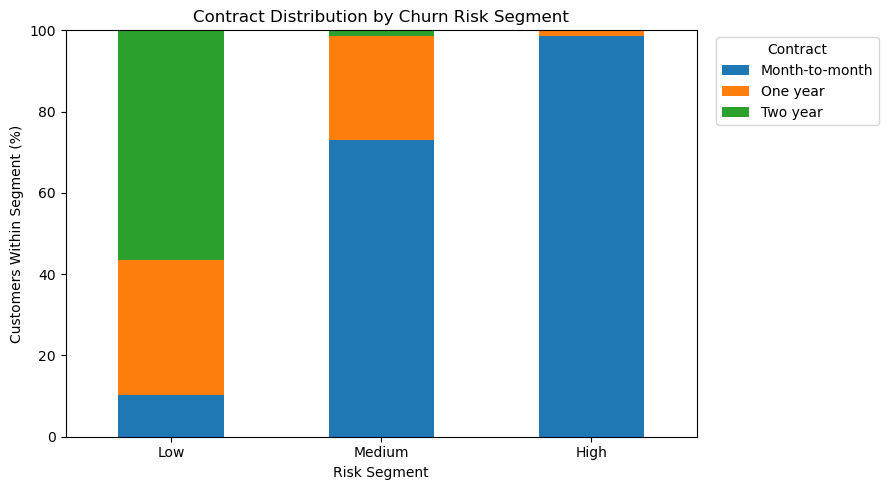

Saved: risk_profile_contract.png


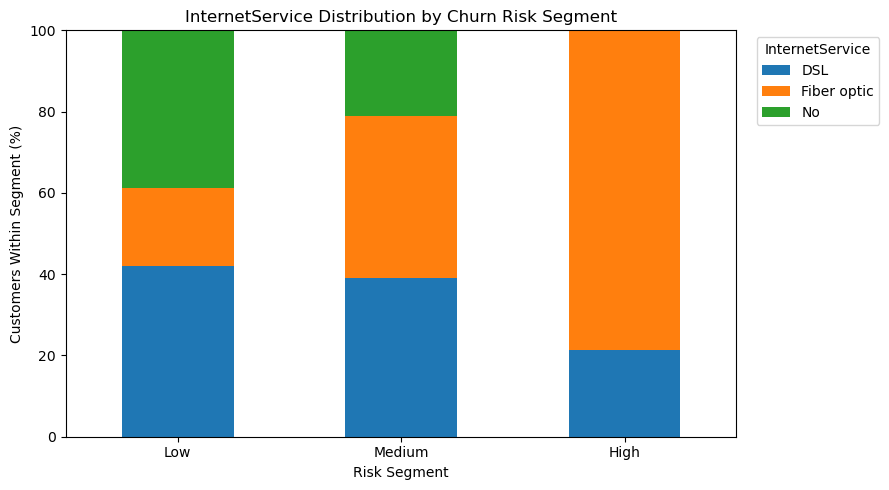

Saved: risk_profile_internetservice.png


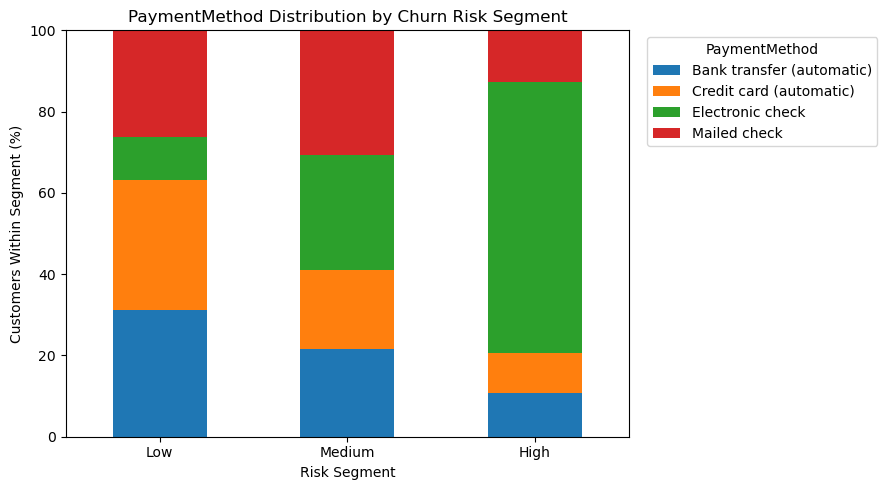

Saved: risk_profile_paymentmethod.png

All customer profile charts generated successfully!


In [13]:
# =========================================================
# Notebook 9 — Cell 5: Risk Segment Profile Visualizations
# =========================================================

import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

risk_order = ["Low", "Medium", "High"]

features_to_plot = [
    "Contract",
    "InternetService",
    "PaymentMethod"
]

for feature in features_to_plot:

    # Percentage distribution within each risk segment
    profile_pct = pd.crosstab(
        customer_profiles["Risk_Segment"],
        customer_profiles[feature],
        normalize="index"
    ).mul(100)

    profile_pct = profile_pct.reindex(risk_order)

    # Plot a separate chart for each feature
    ax = profile_pct.plot(
        kind="bar",
        stacked=True,
        figsize=(9, 5)
    )

    ax.set_title(
        f"{feature} Distribution by Churn Risk Segment"
    )
    ax.set_xlabel("Risk Segment")
    ax.set_ylabel("Customers Within Segment (%)")
    ax.set_ylim(0, 100)

    plt.xticks(rotation=0)
    plt.legend(
        title=feature,
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()

    filename = (
        "risk_profile_"
        + feature.lower()
        + ".png"
    )

    output_path = reports_dir / filename

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", output_path.name)

print("\nAll customer profile charts generated successfully!")

=== LOGISTIC REGRESSION FEATURE EXPLANATIONS ===
Total transformed features: 45

Top 15 coefficients by absolute magnitude:
                                  Feature  Coefficient                          Direction
                              num__tenure      -1.1526 Decreases predicted churn log-odds
                   cat__Contract_Two year      -0.7759 Decreases predicted churn log-odds
         cat__InternetService_Fiber optic       0.7124 Increases predicted churn log-odds
                      num__MonthlyCharges      -0.6877 Decreases predicted churn log-odds
             cat__Contract_Month-to-month       0.6560 Increases predicted churn log-odds
                 cat__InternetService_DSL      -0.6278 Decreases predicted churn log-odds
                        num__TotalCharges       0.4873 Increases predicted churn log-odds
     cat__TechSupport_No internet service      -0.2792 Decreases predicted churn log-odds
cat__DeviceProtection_No internet service      -0.2792 Decreases p

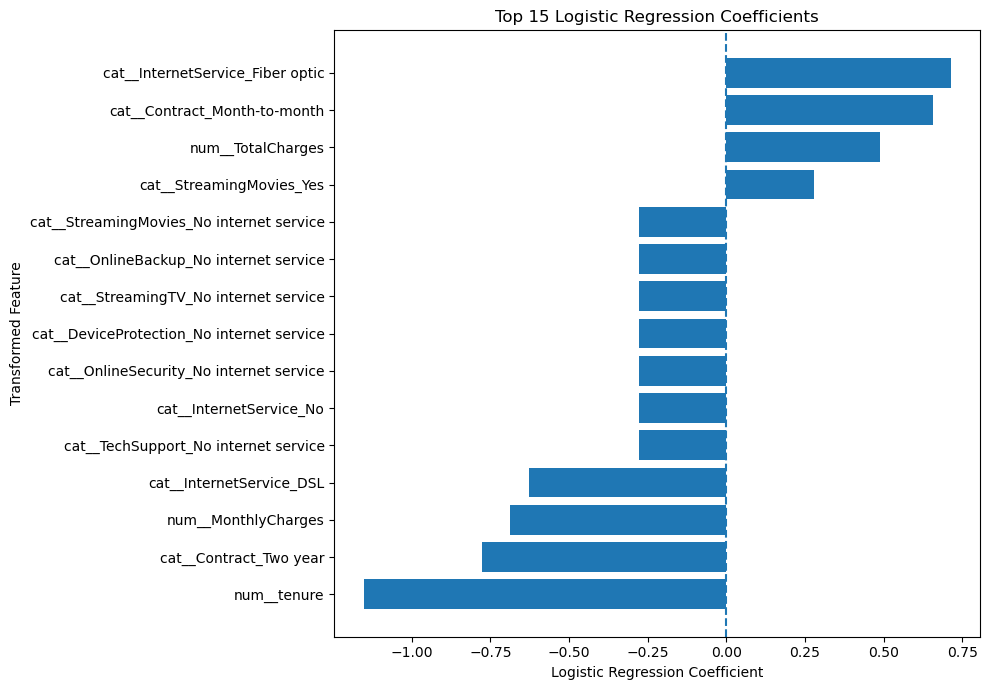


Saved: churn_feature_explanations.csv
Saved: churn_feature_importance.png
Feature explainability analysis completed successfully!


In [14]:
# =========================================================
# Notebook 9 — Cell 6: Logistic Regression Explainability
# =========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Extract the fitted preprocessing and model
preprocessor = model.named_steps["preprocessing"]
classifier = model.named_steps["model"]

# 2. Retrieve transformed feature names and coefficients
feature_names = preprocessor.get_feature_names_out()
coefficients = classifier.coef_[0]

assert len(feature_names) == len(coefficients)

# 3. Create coefficient table
feature_explanations = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

feature_explanations["Absolute_Coefficient"] = (
    feature_explanations["Coefficient"].abs()
)

feature_explanations["Direction"] = np.where(
    feature_explanations["Coefficient"] > 0,
    "Increases predicted churn log-odds",
    "Decreases predicted churn log-odds"
)

feature_explanations = feature_explanations.sort_values(
    "Absolute_Coefficient",
    ascending=False
).reset_index(drop=True)

print("=== LOGISTIC REGRESSION FEATURE EXPLANATIONS ===")

print("Total transformed features:", len(feature_explanations))

print("\nTop 15 coefficients by absolute magnitude:")
print(
    feature_explanations.head(15)[
        ["Feature", "Coefficient", "Direction"]
    ].round(4).to_string(index=False)
)

# 4. Plot top 15 coefficients
top_features = (
    feature_explanations.head(15)
    .sort_values("Coefficient")
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(0, linestyle="--")

plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Transformed Feature")
plt.title("Top 15 Logistic Regression Coefficients")

plt.tight_layout()

plt.savefig(
    reports_dir / "churn_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 5. Save coefficient explanations
feature_explanations.to_csv(
    reports_dir / "churn_feature_explanations.csv",
    index=False
)

print("\nSaved: churn_feature_explanations.csv")
print("Saved: churn_feature_importance.png")
print("Feature explainability analysis completed successfully!")

=== INDIVIDUAL HIGH-RISK CUSTOMER ===
Training row index: 1615
Model risk score: 0.9387
Classification threshold: 0.6

Customer characteristics:
 tenure       Contract InternetService  MonthlyCharges OnlineSecurity TechSupport
      1 Month-to-month     Fiber optic           93.55             No          No

Top 12 feature contributions:
                            Feature  Contribution
                        num__tenure        1.4772
   cat__InternetService_Fiber optic        0.7124
       cat__Contract_Month-to-month        0.6560
                num__MonthlyCharges       -0.6531
                  num__TotalCharges       -0.4716
           cat__StreamingMovies_Yes        0.2768
               cat__StreamingTV_Yes        0.2641
cat__PaymentMethod_Electronic check        0.2389
             cat__OnlineSecurity_No        0.1980
                cat__TechSupport_No        0.1640
              binary__SeniorCitizen        0.1510
             cat__MultipleLines_Yes        0.1341


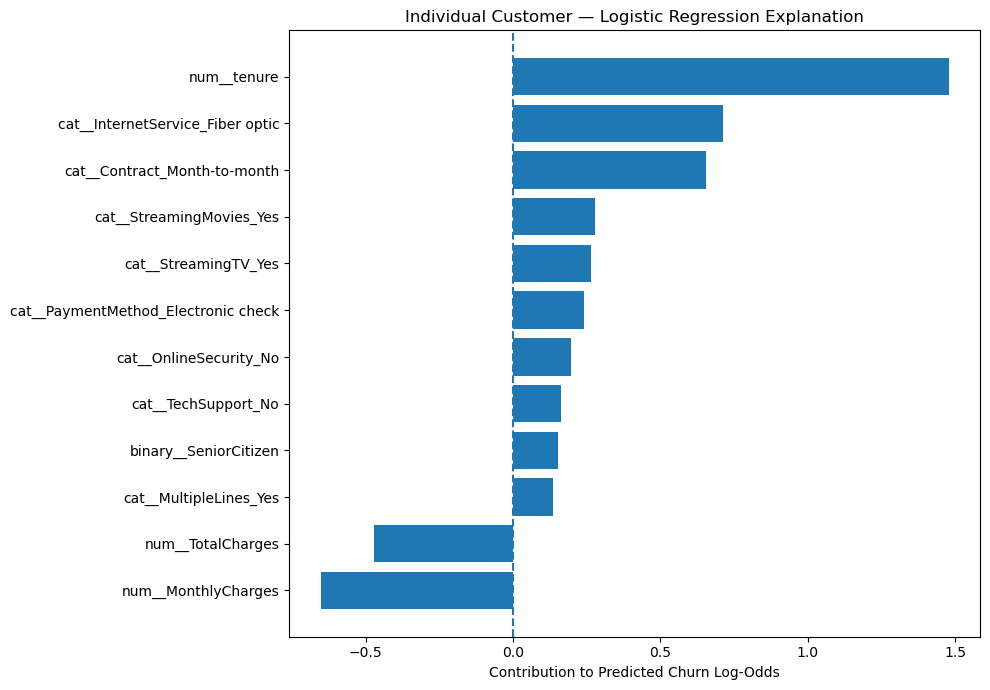


Saved: individual_customer_explanation.csv
Saved: individual_customer_explanation.png
Individual explanation completed successfully!


In [15]:
# =========================================================
# Notebook 9 — Cell 7: Individual Customer Explanation
# =========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Select the highest-scoring training customer
customer_idx = int(
    customer_profiles["Churn_Risk_Score"].idxmax()
)

customer = X_train.loc[[customer_idx]]

# Get predicted risk score
customer_score = float(
    model.predict_proba(customer)[0, 1]
)

# Transform the customer's features using the fitted preprocessor
transformed = preprocessor.transform(customer)

if hasattr(transformed, "toarray"):
    transformed = transformed.toarray()

transformed_values = np.asarray(
    transformed
).reshape(-1)

# Calculate each feature's contribution to log-odds
contributions = transformed_values * coefficients

# Create individual explanation table
individual_explanation = pd.DataFrame({
    "Feature": feature_names,
    "Transformed_Value": transformed_values,
    "Coefficient": coefficients,
    "Contribution": contributions
})

individual_explanation["Absolute_Contribution"] = (
    individual_explanation["Contribution"].abs()
)

individual_explanation = individual_explanation.sort_values(
    "Absolute_Contribution",
    ascending=False
)

# Verify that contributions reconstruct the model prediction
intercept = float(classifier.intercept_[0])

reconstructed_log_odds = (
    intercept + contributions.sum()
)

reconstructed_score = 1 / (
    1 + np.exp(-reconstructed_log_odds)
)

assert np.isclose(
    customer_score,
    reconstructed_score,
    atol=1e-8
)

print("=== INDIVIDUAL HIGH-RISK CUSTOMER ===")
print("Training row index:", customer_idx)
print("Model risk score:", round(customer_score, 4))
print("Classification threshold:", selected_threshold)

print("\nCustomer characteristics:")
print(
    customer[[
        "tenure",
        "Contract",
        "InternetService",
        "MonthlyCharges",
        "OnlineSecurity",
        "TechSupport"
    ]].to_string(index=False)
)

print("\nTop 12 feature contributions:")
print(
    individual_explanation[
        ["Feature", "Contribution"]
    ].head(12).round(4).to_string(index=False)
)

# Plot top 12 contributions
top_contributions = (
    individual_explanation.head(12)
    .sort_values("Contribution")
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_contributions["Feature"],
    top_contributions["Contribution"]
)

plt.axvline(0, linestyle="--")
plt.xlabel("Contribution to Predicted Churn Log-Odds")
plt.title("Individual Customer — Logistic Regression Explanation")
plt.tight_layout()

plt.savefig(
    reports_dir / "individual_customer_explanation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save output
individual_explanation.to_csv(
    reports_dir / "individual_customer_explanation.csv",
    index=False
)

print("\nSaved: individual_customer_explanation.csv")
print("Saved: individual_customer_explanation.png")
print("Individual explanation completed successfully!")

In [16]:
# =========================================================
# Notebook 9 — Cell 8: Retention Strategy Recommendations
# =========================================================

import pandas as pd
from pathlib import Path

recommendations = pd.DataFrame([
    {
        "Risk_Segment": "High",
        "Priority": "High",
        "Customer_Profile": (
            "Often month-to-month, shorter tenure, "
            "fiber optic internet, electronic check"
        ),
        "Recommended_Action": (
            "Prioritize personalized retention outreach, "
            "review billing and service concerns, and "
            "offer suitable contract options"
        ),
        "Business_Rationale": (
            "These customers receive higher model-estimated "
            "churn scores and may benefit from targeted attention"
        )
    },
    {
        "Risk_Segment": "Medium",
        "Priority": "Medium",
        "Customer_Profile": (
            "Intermediate tenure and model-estimated churn risk"
        ),
        "Recommended_Action": (
            "Provide proactive support, service-quality checks, "
            "and relevant loyalty communications"
        ),
        "Business_Rationale": (
            "Early engagement may help address customer concerns "
            "before they become more serious"
        )
    },
    {
        "Risk_Segment": "Low",
        "Priority": "Low",
        "Customer_Profile": (
            "Often longer tenure and longer-term contracts"
        ),
        "Recommended_Action": (
            "Maintain reliable service, regular communication, "
            "and appropriate loyalty benefits"
        ),
        "Business_Rationale": (
            "Maintain customer satisfaction without spending "
            "disproportionate retention resources"
        )
    }
])

print("=== CUSTOMER RETENTION RECOMMENDATIONS ===")
print(recommendations.to_string(index=False))

recommendations.to_csv(
    reports_dir / "retention_recommendations.csv",
    index=False
)

print("\nSaved: retention_recommendations.csv")
print("Retention recommendations completed successfully!")

=== CUSTOMER RETENTION RECOMMENDATIONS ===
Risk_Segment Priority                                                             Customer_Profile                                                                                                   Recommended_Action                                                                                  Business_Rationale
        High     High Often month-to-month, shorter tenure, fiber optic internet, electronic check Prioritize personalized retention outreach, review billing and service concerns, and offer suitable contract options These customers receive higher model-estimated churn scores and may benefit from targeted attention
      Medium   Medium                           Intermediate tenure and model-estimated churn risk                               Provide proactive support, service-quality checks, and relevant loyalty communications                 Early engagement may help address customer concerns before they become more serious
         

## Secondary Lens — High-Risk Customer Profiling and Explainability

### 1. Objective

The secondary objective of this project is to identify customers with higher model-estimated churn risk, examine their characteristics, explain the selected model's predictions, and propose potential retention strategies.

The analysis uses the final Balanced Logistic Regression model selected in Notebook 7, with a classification threshold of 0.60.

### 2. Customer Risk Segmentation

The 5,634 training customers were divided into three analytical risk groups:

| Risk Segment | Customers | Percentage |
|---|---:|---:|
| Low (score below 0.30) | 2,375 | 42.16% |
| Medium (0.30–below 0.60) | 1,397 | 24.80% |
| High (0.60 and above) | 1,862 | 33.05% |

The average tenure of high-risk customers was approximately 14.97 months, compared with 49.10 months among low-risk customers.

High-risk customers also had higher average monthly charges (78.21 versus 55.62).

### 3. High-Risk Customer Characteristics

Among customers assigned to the high-risk segment:

- 98.60% had month-to-month contracts.
- 78.68% used fiber optic internet.
- 66.76% paid by electronic check.

These characteristics were considerably more common in the high-risk segment than in the low-risk segment.

These findings describe associations with model-estimated churn risk, not causal relationships.

### 4. Global Model Explainability

The Logistic Regression model produced 45 transformed features.

Important coefficients included:

- Tenure: -1.1526
- Two-year contract: -0.7759
- Fiber optic internet: +0.7124
- Month-to-month contract: +0.6560
- Monthly charges: -0.6877

Positive coefficients increase predicted churn log-odds, while negative coefficients decrease them, conditional on the other transformed features.

Because the input features include standardized numerical variables, one-hot-encoded categories, and correlated predictors, coefficient magnitudes require careful interpretation.

### 5. Individual Customer Explanation

An illustrative high-risk training customer had:

- Tenure: 1 month
- Contract: Month-to-month
- Internet service: Fiber optic
- Monthly charges: 93.55
- Online security: No
- Technical support: No
- Model-estimated risk score: 0.9387

Important positive contributions included short tenure, fiber optic service, and month-to-month contract status.

The explanation was calculated from each transformed feature value multiplied by its fitted Logistic Regression coefficient. Together with the model intercept, these contributions reconstruct the prediction in log-odds space.

### 6. Proposed Retention Strategies

**High-risk customers:** Prioritize personalized outreach, investigate billing and service concerns, and offer suitable contract options.

**Medium-risk customers:** Provide proactive support, service-quality checks, and relevant loyalty communications.

**Low-risk customers:** Maintain reliable service, customer communication, and appropriate loyalty benefits.

These are proposed strategies. Their effectiveness and financial return have not been experimentally evaluated.

### 7. Limitations

- Customer profiles were generated using a model fitted on the same 5,634 training records. Therefore, the analysis is descriptive and should not be treated as independently validated model performance.
- The selected Logistic Regression model showed probability-calibration limitations in Notebook 8. Its outputs should be interpreted as relative model-estimated risk scores rather than precisely calibrated churn probabilities.
- Risk segment boundaries are analytical choices. Only the 0.60 classification threshold was fixed during model selection.
- Feature coefficients and customer profiles describe statistical associations and model behavior, not proven causes of churn.
- The individual example was selected as the highest-scoring training customer and should not be regarded as a representative customer.

### 8. Conclusion

The secondary-lens analysis demonstrates how the selected churn-classification model can support customer prioritization and interpretable business insights.

The analysis identified model-defined high-risk customers who commonly had short tenure, month-to-month contracts, fiber optic internet service, and electronic check payments.

The findings provide a foundation for designing and evaluating targeted retention strategies, while acknowledging limitations in probability calibration and causal interpretation.